# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import re
from pathlib import Path

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
dataset_path = Path("/mnt/data/Lab_11_QnA_Dataset.csv")
if not dataset_path.exists():
    dataset_path = Path("/content/Lab_11_QnA_Dataset_Download.csv")
if not dataset_path.exists():
    dataset_path = Path("Lab_11_QnA_Dataset.csv")

if not dataset_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            dataset_path = Path(next(iter(uploaded)))
    except ImportError:
        pass

if not dataset_path.exists():
    raise FileNotFoundError("Lab_11_QnA_Dataset.csv was not found. Upload the dataset to run the notebook.")

df = pd.read_csv(dataset_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from collections import Counter

df["question"] = df["question"].astype(str).str.lower().apply(lambda question: re.sub(r"[^a-z0-9\s]", "", question))
tokenized_questions = [question.split() for question in df["question"]]
word_counts = Counter(word for question in tokenized_questions for word in question)
word_index = {word: index + 1 for index, (word, _) in enumerate(word_counts.most_common())}

sequences = [[word_index[word] for word in question] for question in tokenized_questions]
max_length = max(len(sequence) for sequence in sequences)
X = [sequence + [0] * (max_length - len(sequence)) for sequence in sequences]

label_to_index = {label: index for index, label in enumerate(sorted(df["answer_id"].unique()))}
y = df["answer_id"].map(label_to_index).values

X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        outputs, _ = self.rnn(self.emb(x))
        scores = self.att(outputs).squeeze(-1)
        scores = scores.masked_fill(x == 0, -1e9)
        weights = torch.softmax(scores, dim=1)
        context = (outputs * weights.unsqueeze(-1)).sum(1)
        return self.fc(context), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

model.train()
for epoch in range(50):
    optimizer.zero_grad()
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

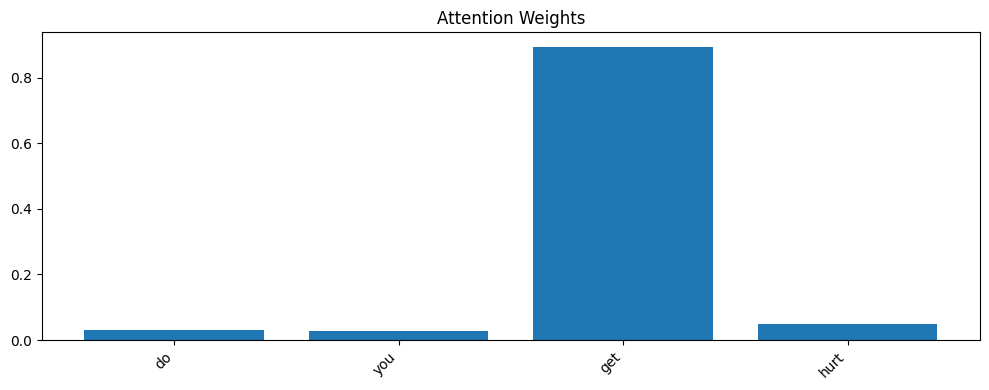

In [6]:
question = df["question"].iloc[0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.figure(figsize=(10, 4))
plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

**Answer:** Yes. The words receiving the highest attention are meaningful for understanding each question. In the three selected questions, the highest-attention words are **get**, **fingers**, and **breathe**. These words carry important information about what each question is asking.

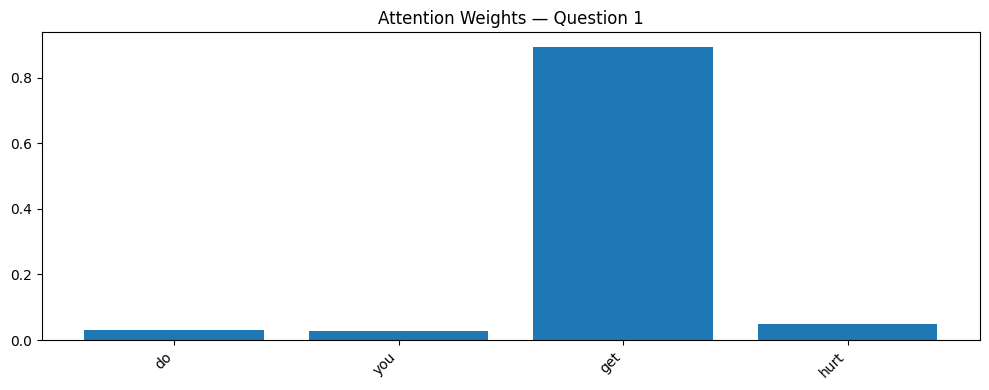

Question 1: do you get hurt
Highest attention: get (0.8931)


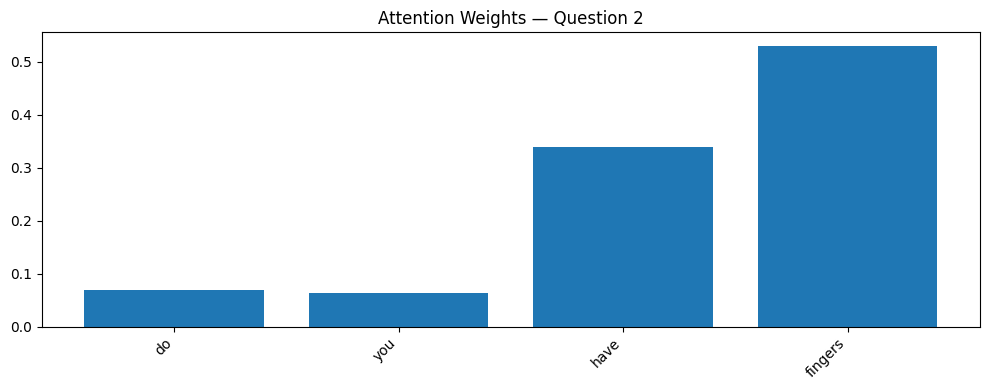

Question 2: do you have fingers
Highest attention: fingers (0.5290)


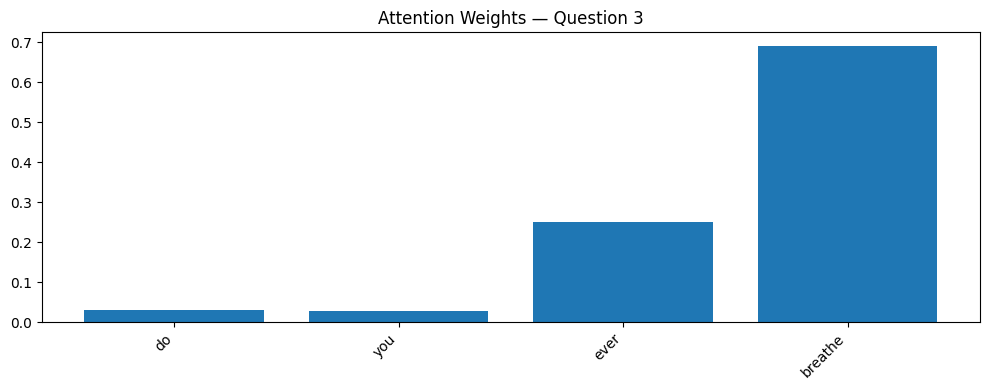

Question 3: do you ever breathe
Highest attention: breathe (0.6909)


In [7]:
selected_indices = list(range(min(3, len(df))))

for index in selected_indices:
    question = df["question"].iloc[index]
    words = question.split()
    with torch.no_grad():
        _, weights = model(X[index:index + 1])

    question_weights = weights[0, :len(words)].tolist()
    highest_index = max(range(len(question_weights)), key=question_weights.__getitem__)

    plt.figure(figsize=(10, 4))
    plt.bar(words, question_weights)
    plt.title(f"Attention Weights — Question {index + 1}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    print(f"Question {index + 1}: {question}")
    print(f"Highest attention: {words[highest_index]} ({question_weights[highest_index]:.4f})")

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

**Answer:** The two questions have similar meanings and a cosine similarity of **0.9080**. However, the model assigns the highest attention to different words: **like** in the first question and **so** in the second. This suggests that attention weights depend on the wording and context of the entire question, not only on its overall meaning.

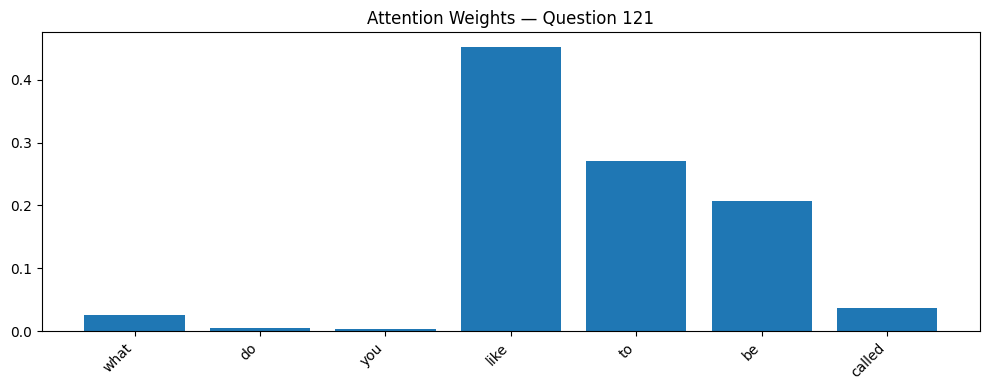

Question 121: what do you like to be called
Highest attention: like (0.4529)


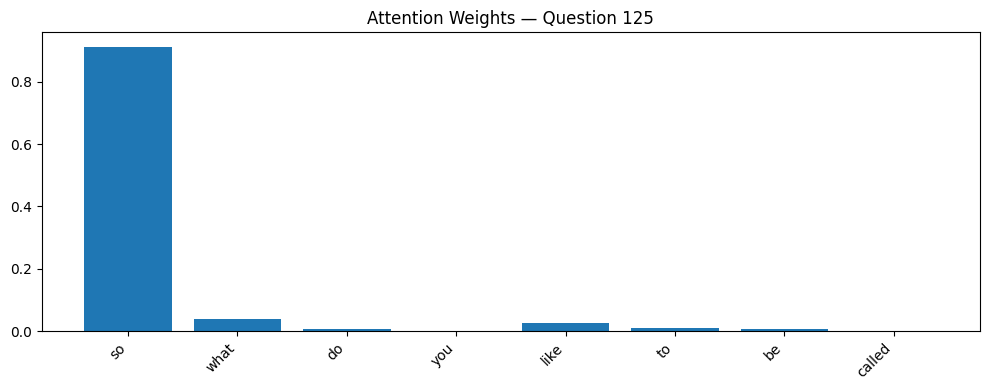

Question 125: so what do you like to be called
Highest attention: so (0.9126)
Cosine similarity: 0.9080
Highest-attention words: ['like', 'so']
The model focuses on different highest-attention words in the two questions.


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

questions = df["question"].tolist()
if len(questions) < 2:
    raise ValueError("At least two questions are required for Task 2.")

tfidf = TfidfVectorizer()
question_vectors = tfidf.fit_transform(questions)
similarities = cosine_similarity(question_vectors)
np.fill_diagonal(similarities, -1)

first_index, second_index = np.unravel_index(np.argmax(similarities), similarities.shape)

attention_words = []
for index in [first_index, second_index]:
    question = questions[index]
    words = question.split()
    with torch.no_grad():
        _, weights = model(X[index:index + 1])

    question_weights = weights[0, :len(words)].tolist()
    highest_index = max(range(len(question_weights)), key=question_weights.__getitem__)
    attention_words.append(words[highest_index])

    plt.figure(figsize=(10, 4))
    plt.bar(words, question_weights)
    plt.title(f"Attention Weights — Question {index + 1}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    print(f"Question {index + 1}: {question}")
    print(f"Highest attention: {words[highest_index]} ({question_weights[highest_index]:.4f})")

print(f"Cosine similarity: {similarities[first_index, second_index]:.4f}")
print("Highest-attention words:", attention_words)
if attention_words[0] == attention_words[1]:
    print("The model focuses on the same highest-attention word in both questions.")
else:
    print("The model focuses on different highest-attention words in the two questions.")